# Chapter 7 — Deep RBMs

Companion notebook for Stone, *Artificial Intelligence Engines* (2020), Chapter 7.
A **restricted Boltzmann machine** (RBM) has a visible layer $v$ and a hidden layer $h$ with no
connections within a layer, so the conditional distributions factorise (Eqs 7.4, 7.6):
$$p(h|v)=\prod_{j=1}^{H} p(h_j|v), \qquad p(v|h)=\prod_{i=1}^{V} p(v_i|h).$$
Each unit is on with probability $P = (1+e^{-u})^{-1}$ (Eq 7.8), where $u_j=\sum_i w_{ij}v_i$ (Eq 7.7)
includes a bias unit with constant state $-1$ (implemented here as an explicit bias vector, $b=-w_{\rm bias}$).

The implementation lives in `scripts/rbm.py`.

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from aie.data import digits
from aie.plotting import show_image_grid
from scripts.rbm import RBM, RBMStack, unroll, random_autoencoder, fine_tune, encode

## Data
`aie.data.digits()` is a small offline stand-in for MNIST: 12×12 = 144-pixel digit images with
pixel values in $[0,1]$, which the RBM treats as probabilities.

(1000, 144) 0.0 1.0


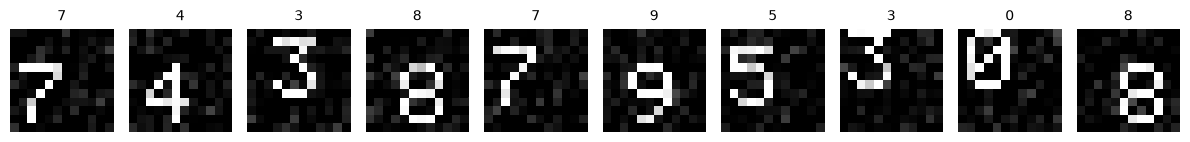

In [2]:
X_img, y = digits(n_per_class=100, seed=0)
X = X_img.reshape(len(X_img), -1)
print(X.shape, X.min(), X.max())
show_image_grid(list(X_img[:10]), titles=[str(t) for t in y[:10]], cols=10, figsize=(12, 1.6));

## Contrastive divergence
Following the pseudocode box on p. 93:

* **Wake**: clamp $v_t = x_t$, compute $P_{jt}$ and record $E[v_iP_j]_{\rm Wake}\approx\frac1T\sum_t v_{it}P_{jt}$ (Eq 7.9).
* **Sleep**: for $k=1\dots N_{CD}$ sample binary $h^k$, compute $P^k_{it}$, sample binary $v^k$, compute
  $P^k_{jt}$; record $E[P_iP_j]_{\rm Sleep}\approx\frac1T\sum_t P^{N_{CD}}_{it}P^{N_{CD}}_{jt}$ (Eq 7.11).
* **Update**: $\Delta w_{ij}=\epsilon\,(E[v_iP_j]_{\rm Wake}-E[P_iP_j]_{\rm Sleep})$ (Eq 7.12).

First a sanity check on a tiny RBM (4 visible, 3 hidden) where the exact log-likelihood can be
computed by enumerating all $2^4$ visible vectors, using the free energy
$F(v)=-v\cdot b_v-\sum_j\log(1+e^{u_j})$ with $p(v)=e^{-F(v)}/Z$.

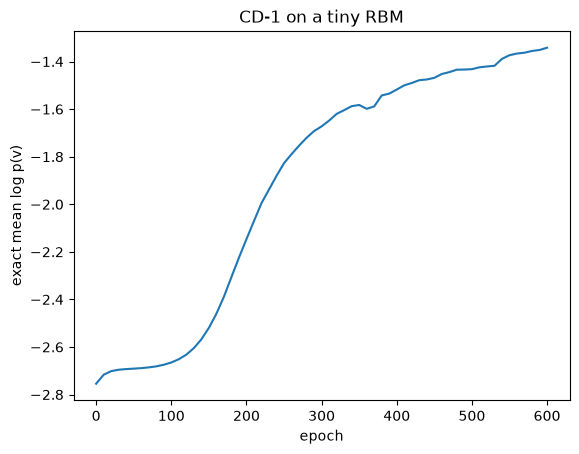

In [3]:
patterns = np.array([[1, 1, 0, 0], [0, 0, 1, 1], [1, 1, 0, 0], [0, 0, 1, 1], [1, 0, 1, 0]], float)
tiny = RBM(4, 3, seed=0, weight_scale=0.1)
ll = [tiny.log_likelihood(patterns)]
for _ in range(60):
    tiny.fit(patterns, n_epochs=10, lr=0.1, batch_size=5)
    ll.append(tiny.log_likelihood(patterns))
plt.plot(np.arange(len(ll)) * 10, ll)
plt.xlabel('epoch'); plt.ylabel('exact mean log p(v)'); plt.title('CD-1 on a tiny RBM');

## An RBM on digits
A 144-64 RBM trained with CD-1 (with a little momentum). We monitor the reconstruction error
of the deterministic up–down pass $v\to P(h|v)\to P(v|h)$.

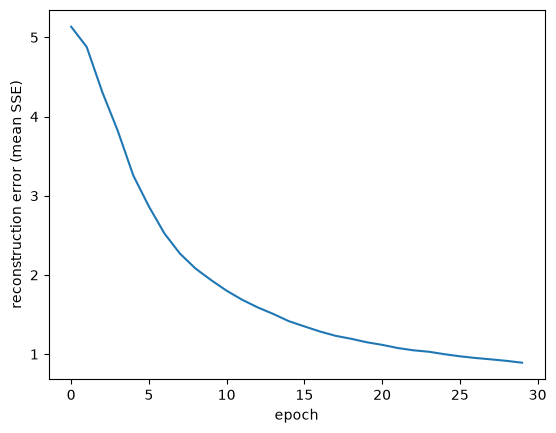

In [4]:
rbm = RBM(144, 64, seed=0).fit(X, n_epochs=30, lr=0.1, batch_size=20, momentum=0.5)
plt.plot(rbm.history); plt.xlabel('epoch'); plt.ylabel('reconstruction error (mean SSE)');

**Learned filters.** Each hidden unit's incoming weight vector $w_{\cdot j}$, reshaped to 12×12
(each rescaled to $[0,1]$ for display).

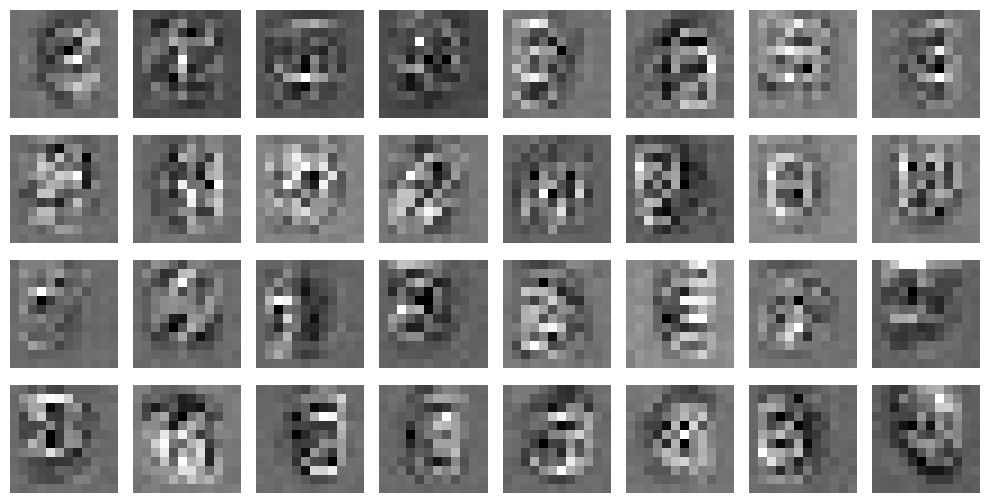

In [5]:
def rescale(w):
    return (w - w.min()) / (w.max() - w.min() + 1e-12)
filters = [rescale(rbm.W[:, j].reshape(12, 12)) for j in range(32)]
show_image_grid(filters, cols=8, figsize=(10, 5.2));

**Reconstructions** (top: data, bottom: $P(v|P(h|v))$).

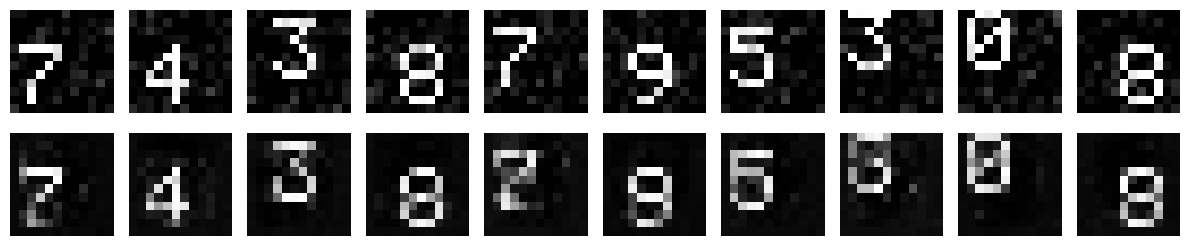

In [6]:
idx = np.arange(10)
recon = rbm.reconstruct(X[idx])
show_image_grid(list(X_img[idx]) + list(recon.reshape(-1, 12, 12)), cols=10, figsize=(12, 2.8));

**Samples from Gibbs chains.** Starting from random binary noise, we alternately sample
$h\sim p(h|v)$ and $v\sim p(v|h)$ (block Gibbs sampling) and display $P(v|h)$ after
various numbers of steps.

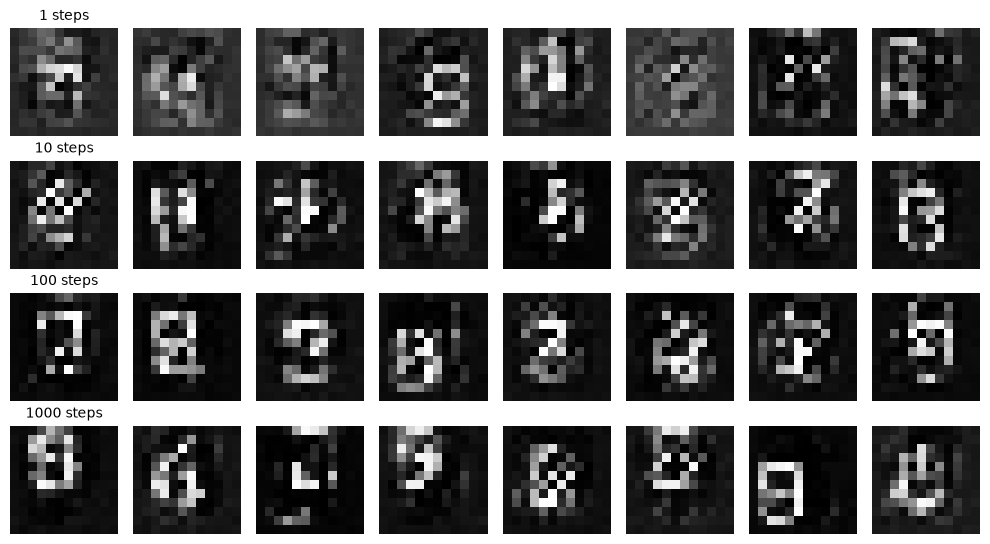

In [7]:
rng = np.random.default_rng(1)
V0 = (rng.random((8, 144)) < 0.2).astype(float)
rows, steps = [], [1, 10, 100, 1000]
for n in steps:
    rbm.rng = np.random.default_rng(2)
    rows += list(rbm.gibbs_chain(V0, n).reshape(-1, 12, 12))
fig = show_image_grid(rows, titles=[f'{s} steps' if i % 8 == 0 else '' for s in steps for i in range(8)],
                      cols=8, figsize=(10, 5.5))

## Deep autoencoder network (Section 7.4)
The book's DAN (Figs 7.4–7.5) pre-trains a 784-1000-500-250-30 stack of RBMs on MNIST.
We scale this down to **144-64-32-8**. Each RBM is trained on the hidden probabilities of the
one below (greedy layer-wise pre-training). The stack is then *unrolled*: the encoder is
duplicated and flipped to form a decoder with transposed weights, every binary unit is replaced
by its probability $P$, and the whole network is fine-tuned with backprop on
$E=\frac1T\sum_t\frac12|x_t-x'_t|^2$.

max |unrolled - stack up/down|: 0.0


final error: pre-trained 0.743, random 4.722


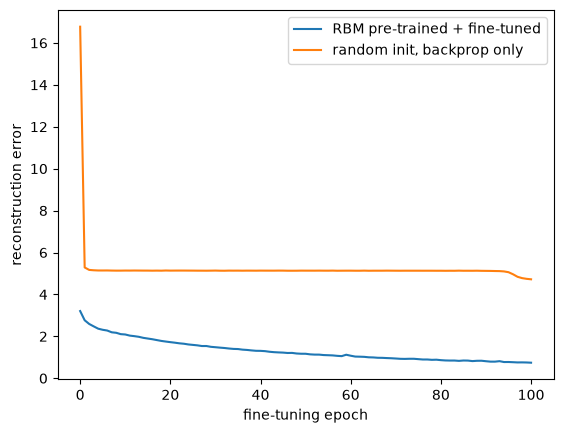

In [8]:
sizes = [144, 64, 32, 8]
stack = RBMStack(sizes, seed=0).pretrain(X, n_epochs=30, lr=0.1, batch_size=20, momentum=0.5)
dan = unroll(stack)
print('max |unrolled - stack up/down|:', np.abs(dan.forward(X) - stack.reconstruct(X)).max())
hist_pre = fine_tune(dan, X, n_epochs=100, lr=0.1, momentum=0.9, seed=0)
rand = random_autoencoder(sizes, seed=0)
hist_rand = fine_tune(rand, X, n_epochs=100, lr=0.1, momentum=0.9, seed=0)
plt.plot(hist_pre, label='RBM pre-trained + fine-tuned')
plt.plot(hist_rand, label='random init, backprop only')
plt.xlabel('fine-tuning epoch'); plt.ylabel('reconstruction error'); plt.legend()
print(f'final error: pre-trained {hist_pre[-1]:.3f}, random {hist_rand[-1]:.3f}')

As Hinton and Salakhutdinov observed (quoted on p. 95), the randomly initialised deep
sigmoid autoencoder makes slow progress (it tends to reconstruct the average image), whereas
the pre-trained network starts from a good solution and improves further with fine-tuning.
Rows below: data, pre-trained DAN, random-init autoencoder.

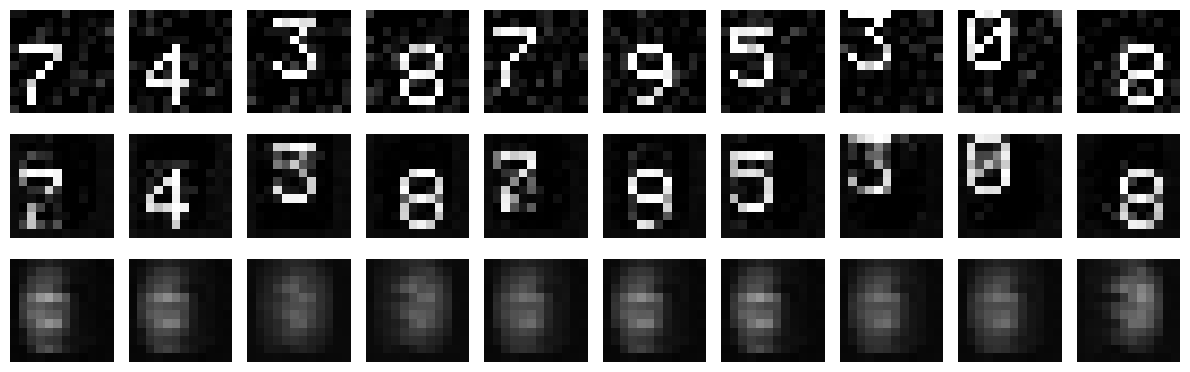

In [9]:
idx = np.arange(10)
show_image_grid(list(X_img[idx]) + list(dan.forward(X[idx]).reshape(-1, 12, 12))
                + list(rand.forward(X[idx]).reshape(-1, 12, 12)), cols=10, figsize=(12, 4));

**Code-layer visualisation.** The 8-unit code is projected onto its first two principal
components and coloured by digit label.

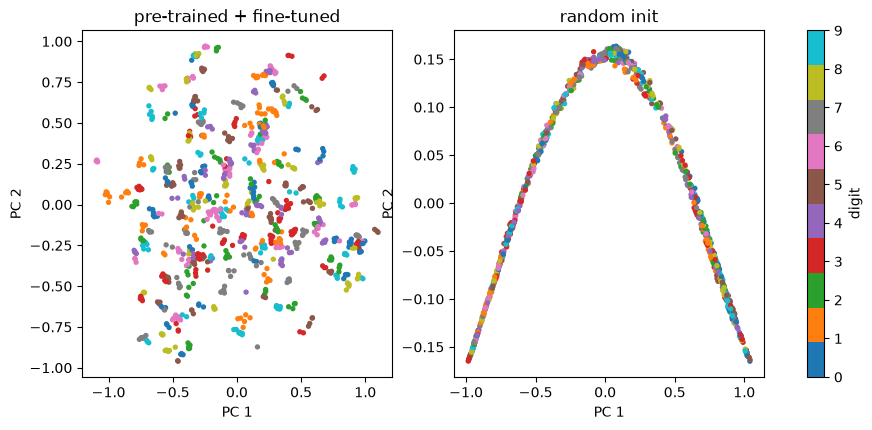

In [10]:
def pca2(C):
    C = C - C.mean(axis=0)
    _, _, Vt = np.linalg.svd(C, full_matrices=False)
    return C @ Vt[:2].T

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, model, title in zip(axes, [dan, rand], ['pre-trained + fine-tuned', 'random init']):
    P2 = pca2(encode(model, X))
    sc = ax.scatter(P2[:, 0], P2[:, 1], c=y, cmap='tab10', s=8)
    ax.set_title(title); ax.set_xlabel('PC 1'); ax.set_ylabel('PC 2')
fig.colorbar(sc, ax=axes, ticks=range(10), label='digit');

## Summary
RBMs learn with only local wake/sleep correlations (Eq 7.12). Stacking them gives a
good initialisation for a deep autoencoder, which backprop then fine-tunes — the key
demonstration (Hinton and Salakhutdinov, 2006) that helped launch deep learning.